In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
import scipy.odr as odr

# Stoßgesetze

## Aufgabe 1

### Ziel: Bestimmung des Mittelwerts und der Messunsicherheit der Auslenkungen von der gestoßenen Kugel

### Gemessen: 
        - Masse der Kugeln
            - Große Kugel und kleine Kugel
        - Pendellänge 
        - Auslenkung der stoßenden Kugel
            - durch Schieber genau festgelegt
        - Auslenkung der gestoßenden Kugel
            - hier wurde die Auslenkung durch Schieber immer wieder angepasst
                    
### Formel:
$$
a_2^{\prime} = \frac{2m_1}{m_1+m_2}a_1
$$

#### Kleine Kugel:
Kugelmasse: $$m_{kl}$$
Auslenkung vor Stoß: $$a_{kl}$$
Auslenkung nach Stoß: $$a_{kl}^{\prime}$$

#### Große Kugel:
Kugelmasse: $$m_{gr}$$
Auslenkung vor Stoß: $$a_{gr}$$
Auslenkung nach Stoß: $$a_{gr}^{\prime}$$

Massenverhältnis: $$ \zeta_{kl, gr} $$


### Unsicherheiten:
- Auslenkung Kugel:
    - Ablesegenauigkeit Skala: $$a = \frac{1 mm}{2\sqrt{6}}$$
- Masse Kugel:
    - Ablesegenauigkeit Waage: $$u_{ablese} = \frac{0.1 g}{2\sqrt{3}}$$


In [2]:
# Messdaten (große Kugel stößt und kleine wird gestoßen)
sp_1 = 22 #Stoßpunkt in cm
a = 0.001/(2*np.sqrt(6)) #Ableseungenauigkeit in m

# erste Messreihe
print("Die erste Messreihe: ")
a_gr_1 = (sp_1-15)*0.01 #in m
print("Auslenkung a_gr_1 vor Stoß in cm: " + str(a_gr_1*100) + " +/- " + str(a*100)) 
a_kl_1_prime_array = (np.array([28.9, 29.1, 28.9, 29.0, 28.9])-sp_1)*0.01 #in m
# Mittelwert
a_kl_1_prime = a_kl_1_prime_array.mean()
print("Mittelwert: " + str(a_kl_1_prime))
# Standardunsicherheit mit studentscher t-Verteilung
a_kl_1_prime_std = (a_kl_1_prime_array.std(ddof=1)/np.sqrt(len(a_kl_1_prime_array)))*1.14
print("Standardunsicherheit: " + str(a_kl_1_prime_std))
# direkt kombinierte Unsicherheit wegen Ableseungenauigkeit
u_a_kl_1_prime = np.sqrt(a_kl_1_prime_std**2 + a**2)
print("Direkt kombinierte Unsicherheit: " + str(u_a_kl_1_prime))
print("Auslenkung a_kl_1 nach Stoß in cm: " + str(a_kl_1_prime*100) + " +/- " + str(u_a_kl_1_prime*100)) 
print("rel. U.: " + str((u_a_kl_1_prime/a_kl_1_prime)))
print()

# zweite Messreihe
print("Die zweite Messreihe:")
a_gr_2 = (sp_1-13)*0.01 #in m
print("Auslenkung a_gr_2 vor Stoß in cm: " + str(a_gr_2*100) + " +/- " + str(a*100)) 
a_kl_2_prime_array = (np.array([32.2, 31.9, 32.0, 32.0, 31.9])-sp_1)*0.01 #in m
# Mittelwert
a_kl_2_prime = a_kl_2_prime_array.mean()
print("Mittelwert: " + str(a_kl_2_prime))
# Standardunsicherheit mit studentscher t-Verteilung
a_kl_2_prime_std = (a_kl_2_prime_array.std(ddof=1)/np.sqrt(len(a_kl_2_prime_array)))*1.14
print("Standardunsicherheit: " + str(a_kl_2_prime_std))
# direkt kombinierte Unsicherheit wegen Ableseungenauigkeit
u_a_kl_2_prime = np.sqrt(a_kl_2_prime_std**2 + a**2)
print("Direkt kombinierte Unsicherheit: " + str(u_a_kl_2_prime))
print("Auslenkung a_kl_2 nach Stoß in cm: " + str(a_kl_2_prime*100) + " +/- " + str(u_a_kl_2_prime*100)) 
print("rel. U.: " + str((u_a_kl_2_prime/a_kl_2_prime)))
print()

# dritte Messreihe
print("Die dritte Messreihe:")
a_gr_3 = (sp_1-11)*0.01 #in m
print("Auslenkung a_gr_3 vor Stoß in cm: " + str(a_gr_3*100) + " +/- " + str(a*100)) 
a_kl_3_prime_array = (np.array([34.8, 34.7, 34.6, 34.7, 34.8])-sp_1)*0.01 #in m
# Mittelwert
a_kl_3_prime = a_kl_3_prime_array.mean()
print("Mittelwert: " + str(a_kl_3_prime))
# Standardunsicherheit mit studentscher t-Verteilung
a_kl_3_prime_std = (a_kl_3_prime_array.std(ddof=1)/np.sqrt(len(a_kl_3_prime_array)))*1.14
print("Standardunsicherheit: " + str(a_kl_3_prime_std))
# direkt kombinierte Unsicherheit wegen Ableseungenauigkeit
u_a_kl_3_prime = np.sqrt(a_kl_3_prime_std**2 + a**2)
print("Direkt kombinierte Unsicherheit: " + str(u_a_kl_3_prime))
print("Auslenkung a_kl_3 nach Stoß in cm: " + str(a_kl_3_prime*100) + " +/- " + str(u_a_kl_3_prime*100)) 
print("rel. U.: " + str((u_a_kl_3_prime/a_kl_3_prime)))
print()

# vierte Messreihe
print("Die vierte Messreihe:")
a_gr_4 = (sp_1-9)*0.01 #in m
print("Auslenkung a_gr_4 vor Stoß in cm: " + str(a_gr_4*100) + " +/- " + str(a*100)) 
a_kl_4_prime_array = (np.array([37.5, 37.7, 37.6, 37.6, 37.6])-sp_1)*0.01 #in m
# Mittelwert
a_kl_4_prime = a_kl_4_prime_array.mean()
print("Mittelwert: " + str(a_kl_4_prime))
# Standardunsicherheit mit studentscher t-Verteilung
a_kl_4_prime_std = (a_kl_4_prime_array.std(ddof=1)/np.sqrt(len(a_kl_4_prime_array)))*1.14
print("Standardunsicherheit: " + str(a_kl_4_prime_std))
# direkt kombinierte Unsicherheit wegen Ableseungenauigkeit
u_a_kl_4_prime = np.sqrt(a_kl_4_prime_std**2 + a**2)
print("Direkt kombinierte Unsicherheit: " + str(u_a_kl_4_prime))
print("Auslenkung a_kl_4 nach Stoß in cm: " + str(a_kl_4_prime*100) + " +/- " + str(u_a_kl_4_prime*100)) 
print("rel. U.: " + str((u_a_kl_4_prime/a_kl_4_prime)))
print()

# fünfte Messreihe
print("Die fünfte Messreihe:")
a_gr_5 = (sp_1-7)*0.01 #in m
print("Auslenkung a_gr_5 vor Stoß in cm: " + str(a_gr_5*100) + " +/- " + str(a*100)) 
a_kl_5_prime_array = (np.array([40.1, 40.2, 40.2, 40.4, 40.4])-sp_1)*0.01 #in m
# Mittelwert
a_kl_5_prime = a_kl_5_prime_array.mean()
print("Mittelwert: " + str(a_kl_5_prime))
# Standardunsicherheit mit studentscher t-Verteilung
a_kl_5_prime_std = (a_kl_5_prime_array.std(ddof=1)/np.sqrt(len(a_kl_5_prime_array)))*1.14
print("Standardunsicherheit: " + str(a_kl_5_prime_std))
# direkt kombinierte Unsicherheit wegen Ableseungenauigkeit
u_a_kl_5_prime = np.sqrt(a_kl_5_prime_std**2 + a**2)
print("Direkt kombinierte Unsicherheit: " + str(u_a_kl_5_prime))
print("Auslenkung a_kl_5 nach Stoß in cm: " + str(a_kl_5_prime*100) + " +/- " + str(u_a_kl_5_prime*100)) 
print("rel. U.: " + str((u_a_kl_5_prime/a_kl_5_prime)))
print()


Die erste Messreihe: 
Auslenkung a_gr_1 vor Stoß in cm: 7.000000000000001 +/- 0.020412414523193156
Mittelwert: 0.06960000000000001
Standardunsicherheit: 0.0004560000000000067
Direkt kombinierte Unsicherheit: 0.0004996025086673133
Auslenkung a_kl_1 nach Stoß in cm: 6.960000000000001 +/- 0.04996025086673133
rel. U.: 0.007178196963610822

Die zweite Messreihe:
Auslenkung a_gr_2 vor Stoß in cm: 9.0 +/- 0.020412414523193156
Mittelwert: 0.1
Standardunsicherheit: 0.0006244037155558984
Direkt kombinierte Unsicherheit: 0.000656922116134537
Auslenkung a_kl_2 nach Stoß in cm: 10.0 +/- 0.0656922116134537
rel. U.: 0.0065692211613453694

Die dritte Messreihe:
Auslenkung a_gr_3 vor Stoß in cm: 11.0 +/- 0.020412414523193156
Mittelwert: 0.1272
Standardunsicherheit: 0.0004265489420922161
Direkt kombinierte Unsicherheit: 0.0004728748953652069
Auslenkung a_kl_3 nach Stoß in cm: 12.72 +/- 0.04728748953652069
rel. U.: 0.003717569932116406

Die vierte Messreihe:
Auslenkung a_gr_4 vor Stoß in cm: 13.0 +/- 0.0

In [3]:
# Messdaten (kleine Kugel stößt und größe wird gestoßen)

# erste Messreihe
print("Die erste Messreihe: ")
a_kl_1 = (29-sp_1)*0.01 #in m
a_gr_1_prime_array = (sp_1-np.array([15.5, 15.5, 15.5, 15.5, 15.6]))*0.01 #in m
# Mittelwert
a_gr_1_prime = a_gr_1_prime_array.mean()
print("Mittelwert: " + str(a_gr_1_prime))
# Standardunsicherheit mit studentscher t-Verteilung
a_gr_1_prime_std = (a_gr_1_prime_array.std(ddof=1)/np.sqrt(len(a_gr_1_prime_array)))*1.14
print("Standardunsicherheit: " + str(a_gr_1_prime_std))
# direkt kombinierte Unsicherheit wegen Ableseungenauigkeit
u_a_gr_1_prime = np.sqrt(a_gr_1_prime_std**2 + a**2)
print("Direkt kombinierte Unsicherheit: " + str(u_a_gr_1_prime))
print("Auslenkung a_gr_1 nach Stoß in cm: " + str(a_gr_1_prime*100) + " +/- " + str(u_a_gr_1_prime*100)) 
print("rel. U.: " + str((u_a_gr_1_prime/a_gr_1_prime)))
print()

# zweite Messreihe
print("Die zweite Messreihe: ")
a_kl_2 = (32-sp_1)*0.01 #in m
a_gr_2_prime_array = (sp_1-np.array([14, 13.9, 13.9, 13.9, 13.9]))*0.01 #in m
# Mittelwert
a_gr_2_prime = a_gr_2_prime_array.mean()
print("Mittelwert: " + str(a_gr_2_prime))
# Standardunsicherheit mit studentscher t-Verteilung
a_gr_2_prime_std = (a_gr_2_prime_array.std(ddof=1)/np.sqrt(len(a_gr_2_prime_array)))*1.14
print("Standardunsicherheit: " + str(a_gr_2_prime_std))
# direkt kombinierte Unsicherheit wegen Ableseungenauigkeit
u_a_gr_2_prime = np.sqrt(a_gr_2_prime_std**2 + a**2)
print("Direkt kombinierte Unsicherheit: " + str(u_a_gr_2_prime))
print("Auslenkung a_gr_2 nach Stoß in cm: " + str(a_gr_2_prime*100) + " +/- " + str(u_a_gr_2_prime*100)) 
print("rel. U.: " + str((u_a_gr_2_prime/a_gr_2_prime)))
print()

# dritte Messreihe
print("Die dritte Messreihe: ")
a_kl_3 = (35-sp_1)*0.01 #in m
a_gr_3_prime_array = (sp_1-np.array([12.5, 12.4, 12.4, 12.4, 12.5]))*0.01 #in m
# Mittelwert
a_gr_3_prime = a_gr_3_prime_array.mean()
print("Mittelwert: " + str(a_gr_3_prime))
# Standardunsicherheit mit studentscher t-Verteilung
a_gr_3_prime_std = (a_gr_3_prime_array.std(ddof=1)/np.sqrt(len(a_gr_3_prime_array)))*1.14
print("Standardunsicherheit: " + str(a_gr_3_prime_std))
# direkt kombinierte Unsicherheit wegen Ableseungenauigkeit
u_a_gr_3_prime = np.sqrt(a_gr_3_prime_std**2 + a**2)
print("Direkt kombinierte Unsicherheit: " + str(u_a_gr_3_prime))
print("Auslenkung a_gr_3 nach Stoß in cm: " + str(a_gr_3_prime*100) + " +/- " + str(u_a_gr_3_prime*100)) 
print("rel. U.: " + str((u_a_gr_3_prime/a_gr_3_prime)))
print()

# vierte Messreihe
print("Die vierte Messreihe: ")
a_kl_4 = (38-sp_1)*0.01 #in m
a_gr_4_prime_array = (sp_1-np.array([11.0, 11.0, 11.1, 11.1, 11.0]))*0.01 #in m
# Mittelwert
a_gr_4_prime = a_gr_4_prime_array.mean()
print("Mittelwert: " + str(a_gr_4_prime))
# Standardunsicherheit mit studentscher t-Verteilung
a_gr_4_prime_std = (a_gr_4_prime_array.std(ddof=1)/np.sqrt(len(a_gr_4_prime_array)))*1.14
print("Standardunsicherheit: " + str(a_gr_4_prime_std))
# direkt kombinierte Unsicherheit wegen Ableseungenauigkeit
u_a_gr_4_prime = np.sqrt(a_gr_4_prime_std**2 + a**2)
print("Direkt kombinierte Unsicherheit: " + str(u_a_gr_4_prime))
print("Auslenkung a_gr_4 nach Stoß in cm: " + str(a_gr_4_prime*100) + " +/- " + str(u_a_gr_4_prime*100)) 
print("rel. U.: " + str((u_a_gr_4_prime/a_gr_4_prime)))
print()

# fünfte Messreihe
print("Die fünfte Messreihe: ")
a_kl_5 = (41-sp_1)*0.01 #in m
a_gr_5_prime_array = (sp_1-np.array([9.4, 9.4, 9.3, 9.3, 9.3]))*0.01 #in m
# Mittelwert
a_gr_5_prime = a_gr_5_prime_array.mean()
print("Mittelwert: " + str(a_gr_5_prime))
# Standardunsicherheit mit studentscher t-Verteilung
a_gr_5_prime_std = (a_gr_5_prime_array.std(ddof=1)/np.sqrt(len(a_gr_5_prime_array)))*1.14
print("Standardunsicherheit: " + str(a_gr_5_prime_std))
# direkt kombinierte Unsicherheit wegen Ableseungenauigkeit
u_a_gr_5_prime = np.sqrt(a_gr_5_prime_std**2 + a**2)
print("Direkt kombinierte Unsicherheit: " + str(u_a_gr_5_prime))
print("Auslenkung a_gr_5 nach Stoß in cm: " + str(a_gr_5_prime*100) + " +/- " + str(u_a_gr_5_prime*100)) 
print("rel. U.: " + str((u_a_gr_5_prime/a_gr_5_prime)))
print()


Die erste Messreihe: 
Mittelwert: 0.0648
Standardunsicherheit: 0.00022800000000000018
Direkt kombinierte Unsicherheit: 0.0003060239642032414
Auslenkung a_gr_1 nach Stoß in cm: 6.4799999999999995 +/- 0.030602396420324137
rel. U.: 0.0047225920401734785

Die zweite Messreihe: 
Mittelwert: 0.08080000000000001
Standardunsicherheit: 0.00022800000000000018
Direkt kombinierte Unsicherheit: 0.0003060239642032414
Auslenkung a_gr_2 nach Stoß in cm: 8.080000000000002 +/- 0.030602396420324137
rel. U.: 0.0037874252995450663

Die dritte Messreihe: 
Mittelwert: 0.09559999999999999
Standardunsicherheit: 0.0002792418306772825
Direkt kombinierte Unsicherheit: 0.0003458940107412483
Auslenkung a_gr_3 nach Stoß in cm: 9.559999999999999 +/- 0.03458940107412483
rel. U.: 0.0036181381876699615

Die vierte Messreihe: 
Mittelwert: 0.1096
Standardunsicherheit: 0.0002792418306772825
Direkt kombinierte Unsicherheit: 0.0003458940107412483
Auslenkung a_gr_4 nach Stoß in cm: 10.96 +/- 0.03458940107412483
rel. U.: 0.003

### Fits

In [4]:
def gerade(x, m, c):
    return m*x + c

In [5]:
a_gr_array = np.array([a_gr_1, a_gr_2, a_gr_3, a_gr_4, a_gr_5])
a_kl_prime_array = np.array([a_kl_1_prime, a_kl_2_prime, a_kl_3_prime, a_kl_4_prime, a_kl_5_prime])
u_skala = 0.001/(2*np.sqrt(6))

#Fit Auslenkung der kleinen Kugel nach Stoß
opt_a_kl_prime, cov_a_kl_prime = optimize.curve_fit(gerade, a_gr_array, a_kl_prime_array, sigma=u_skala * np.ones_like(a_kl_prime_array),
                                  absolute_sigma=True)

m_a_kl_prime, c_a_kl_prime = opt_a_kl_prime
u_m_a_kl_prime, u_c_a_kl_prime= np.sqrt(np.diag(cov_a_kl_prime))

print("Die Steigung beträgt: " + str(m_a_kl_prime) + " +/- " + str(u_m_a_kl_prime))
print("Der y-Achsenabschnitt beträgt: " + str(c_a_kl_prime) + " +/- " + str(u_c_a_kl_prime))

Die Steigung beträgt: 1.4099999999573012 +/- 0.0032274861230909674
Der y-Achsenabschnitt beträgt: -0.028019999995361852 +/- 0.00036657196246972376


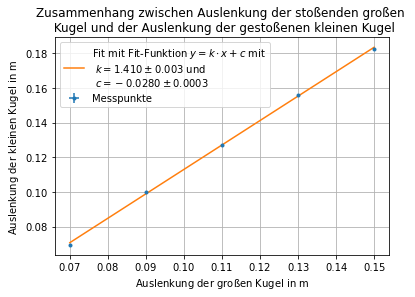

In [6]:
plt.figure()
# gestoßene Kugel: Klein
plt.errorbar(a_gr_array,  a_kl_prime_array, xerr = 0, yerr= u_skala, fmt=".", label = "Messpunkte")
plt.plot(a_gr_array, gerade(a_gr_array, m_a_kl_prime, c_a_kl_prime), label = "Fit mit Fit-Funktion $y = k\cdot x + c$ mit \n $k = 1.410 \pm 0.003$ und \n $c = -0.0280 \pm 0.0003$")

handles, labels = plt.gca().get_legend_handles_labels()
#specify order of items in legend
order = [0, 1]

plt.grid()
plt.ylabel("Auslenkung der kleinen Kugel in $\mathrm{m}$")
plt.xlabel("Auslenkung der großen Kugel in $\mathrm{m}$")
plt.title("Zusammenhang zwischen Auslenkung der stoßenden großen \n Kugel und der Auslenkung der gestoßenen kleinen Kugel")
plt.legend( )#[handles[idx] for idx in order],[labels[idx] for idx in order], loc = "upper left", frameon=False)
plt.savefig('Auslenkung der kleinen Kugel als Funktion der großen Kugel.pdf')

In [7]:
a_kl_array = np.array([a_kl_1, a_kl_2, a_kl_3, a_kl_4, a_kl_5])
a_gr_prime_array = np.array([a_gr_1_prime, a_gr_2_prime, a_gr_3_prime, a_gr_4_prime, a_gr_5_prime])
u_skala = 0.001/(2*np.sqrt(6))

#Fit Auslenkung der kleinen Kugel nach Stoß
opt_a_gr_prime, cov_a_gr_prime = optimize.curve_fit(gerade, a_kl_array, a_gr_prime_array, sigma=u_skala * np.ones_like(a_gr_prime_array),
                                  absolute_sigma=True)

m_a_gr_prime, c_a_gr_prime = opt_a_gr_prime
u_m_a_gr_prime, u_c_a_gr_prime= np.sqrt(np.diag(cov_a_gr_prime))

print("Die Steigung beträgt: " + str(m_a_gr_prime) + " +/- " + str(u_m_a_gr_prime))
print("Der y-Achsenabschnitt beträgt: " + str(c_a_gr_prime) + " +/- " + str(u_c_a_gr_prime))

Die Steigung beträgt: 0.5080000002542696 +/- 0.002151657426405553
Der y-Achsenabschnitt beträgt: 0.029439999963404035 +/- 0.0002942347270400207


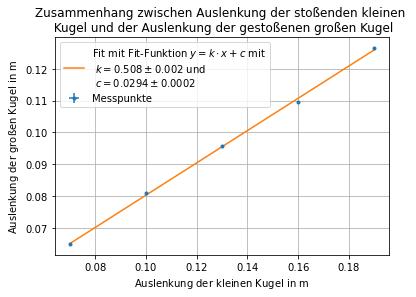

In [8]:
plt.figure()
# gestoßene Kugel: Groß
plt.errorbar(a_kl_array,  a_gr_prime_array, xerr = 0, yerr= u_skala, fmt=".", label = "Messpunkte")
plt.plot(a_kl_array, gerade(a_kl_array, m_a_gr_prime, c_a_gr_prime), label = "Fit mit Fit-Funktion $y = k\cdot x + c$ mit \n $k = 0.508 \pm 0.002$ und \n $c = 0.0294 \pm 0.0002$")

handles, labels = plt.gca().get_legend_handles_labels()
#specify order of items in legend
order = [0, 1]

plt.grid()
plt.ylabel("Auslenkung der großen Kugel in $\mathrm{m}$")
plt.xlabel("Auslenkung der kleinen Kugel in $\mathrm{m}$")
plt.title("Zusammenhang zwischen Auslenkung der stoßenden kleinen \n Kugel und der Auslenkung der gestoßenen großen Kugel")
plt.legend() #[handles[idx] for idx in order],[labels[idx] for idx in order], loc = "upper left", frameon=False)
plt.savefig('Auslenkung der großen Kugel als Funktion der Auslenkung der kleinen Kugel.pdf')

### Massenverhältnis

#### Theorie

In [9]:
#Messdaten Massen
u_ablese = 0.1/(2*np.sqrt(3)) # Waage + Rechteck

m_gr = 512.1 
#u_m_gr = np.sqrt(u_ablese**2 + u_T_0_std_corr**2)
print("große Masse: " +str(m_gr) + " +/- " + str(u_ablese))
m_kl = 176.6
#u_m_kl = 
print("kleine Masse: " +str(m_kl) + " +/- " + str(u_ablese))

große Masse: 512.1 +/- 0.02886751345948129
kleine Masse: 176.6 +/- 0.02886751345948129


$$\zeta_{Theo}= \frac{m_{kl}}{m_{gr}}$$

$$
u_{\zeta_{Theo}} = \sqrt{
\left(\frac{1}{m_{gr}} \cdot u_{m_{kl}} \right)^2 + 
\left(-\frac{m_{kl}}{m_{gr}^2} \cdot u_{m_{gr}} \right)^2
}
$$

In [10]:
zeta_Theo = m_kl/m_gr
u_zeta_Theo = np.sqrt(((1/m_gr)*u_ablese)**2+(-(m_kl/m_gr**2)*u_ablese)**2)
print("Das errechnete Massenverhältnis: " + str(zeta_Theo) + " +/- "  + str(u_zeta_Theo))

Das errechnete Massenverhältnis: 0.344854520601445 +/- 5.962865591028001e-05


#### Experimentel

$$\zeta_{Exp}= \frac{k_1}{k_2}$$

$$
u_{\zeta_{Theo}} = \sqrt{
\left(\frac{1}{k_2} \cdot u_{k_1} \right)^2 + 
\left(-\frac{k_1}{k_2^2} \cdot u_{k_2} \right)^2
}
$$

In [11]:
k_1 = m_a_gr_prime
u_k_1 = u_m_a_gr_prime
k_2 = m_a_kl_prime
u_k_2 = u_m_a_kl_prime

In [12]:
zeta_Exp = k_1/k_2
u_zeta_Exp = np.sqrt(((1/k_2)*u_k_1)**2+(-(k_1/k_2**2)*u_k_2)**2)
print("Das errechnete Massenverhältnis: " + str(zeta_Exp) + " +/- "  + str(u_zeta_Exp))

Das errechnete Massenverhältnis: 0.3602836881345059 +/- 0.0017345839096581744


#### Summe der Steigungen

$$k_{ges} = k_1 + k_2$$

$$
u_{k_{ges}} = \sqrt{
\left(u_{k_1} \right)^2 + 
\left(u_{k_2} \right)^2
}
$$

In [13]:
k_ges = k_1 + k_2
u_k_ges = np.sqrt((u_k_1)**2+(u_k_2)**2)

print("Summe der Steigungen: " + str(k_ges) + " +/- "  + str(u_k_ges))


Summe der Steigungen: 1.918000000211571 +/- 0.0038789555753257774
